In [168]:
import pandas as pd
from tqdm.auto import tqdm
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

tqdm.pandas()

# Load the data

In [169]:
high_pop_songs = pd.read_csv("high_popularity_spotify_data.csv")
low_pop_songs = pd.read_csv("low_popularity_spotify_data.csv")
high_pop_songs.head()

,energy,tempo,danceability,playlist_genre,loudness,liveness,valence,track_artist,time_signature,speechiness,...,instrumentalness,track_album_id,mode,key,duration_ms,acousticness,id,playlist_subgenre,type,playlist_id
0,0.592,157.969,0.521,pop,-7.777,0.122,0.535,"Lady Gaga, Bruno Mars",3,0.0304,...,0.0000,10FLjwfpbxLmW8c25Xyc2N,0,6,251668,0.3080,2plbrEY59IikOBgBGLjaoe,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
1,0.507,104.978,0.747,pop,-10.171,0.117,0.438,Billie Eilish,4,0.0358,...,0.0608,7aJuG4TFXa2hmE4z1yxc3n,1,2,210373,0.2000,6dOtVTDdiauQNBQEDOtlAB,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
2,0.808,108.548,0.554,pop,-4.169,0.159,0.372,Gracie Abrams,4,0.0368,...,0.0000,0hBRqPYPXhr1RkTDG3n4Mk,1,1,166300,0.2140,7ne4VBA60CxGM75vw0EYad,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
3,0.910,112.966,0.670,pop,-4.070,0.304,0.786,Sabrina Carpenter,4,0.0634,...,0.0000,4B4Elma4nNDUyl6D5PvQkj,0,0,157280,0.0939,1d7Ptw3qYcfpdLNL5REhtJ,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
4,0.783,149.027,0.777,pop,-4.477,0.355,0.939,"ROSÉ, Bruno Mars",4,0.2600,...,0.0000,2IYQwwgxgOIn7t3iF6ufFD,0,0,169917,0.0283,5vNRhkKd0yEAg8suGBpjeY,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M


# Now combine the data. But first look at NAs

In [170]:
low_pop_songs.isna().sum()

time_signature              1
track_popularity            0
speechiness                 1
danceability                1
playlist_name               0
track_artist                0
duration_ms                 1
energy                      1
playlist_genre              0
playlist_subgenre           0
track_href                  1
track_name                  0
mode                        1
uri                         1
type                        1
track_album_release_date    0
analysis_url                1
id                          1
instrumentalness            1
track_album_id              0
playlist_id                 0
track_id                    0
valence                     1
key                         1
tempo                       1
loudness                    1
acousticness                1
liveness                    1
track_album_name            0
dtype: int64

In [171]:
high_pop_songs.isna().sum()

energy                      0
tempo                       0
danceability                0
playlist_genre              0
loudness                    0
liveness                    0
valence                     0
track_artist                0
time_signature              0
speechiness                 0
track_popularity            0
track_href                  0
uri                         0
track_album_name            1
playlist_name               0
analysis_url                0
track_id                    0
track_name                  0
track_album_release_date    0
instrumentalness            0
track_album_id              0
mode                        0
key                         0
duration_ms                 0
acousticness                0
id                          0
playlist_subgenre           0
type                        0
playlist_id                 0
dtype: int64

# For dropping NA/s since there were only one row in each original frame dropped it is far more worth it to just drop the rows with missing values rather then imputing anything.

In [172]:
prev_low_shape = low_pop_songs.shape[0]
low_pop_songs = low_pop_songs.dropna()
print(f"In low pop songs there were {prev_low_shape-low_pop_songs.shape[0]} rows with na values droped")

In low pop songs there were 1 rows with na values droped


In [173]:
prev_high_shape = high_pop_songs.shape[0]
high_pop_songs = high_pop_songs.dropna()
print(f"In high pop songs there were {prev_high_shape-high_pop_songs.shape[0]} rows with na values droped")

In high pop songs there were 1 rows with na values droped


# Since this col only has one value in each DF it is not worth keeping.

In [174]:
print(f"The unique values in type col for low popularity songs is: {list(low_pop_songs['type'].unique())}")
print(f"The unique values in type col for high popularity songs is: {list(high_pop_songs['type'].unique())}")

The unique values in type col for low popularity songs is: ['audio_features']
The unique values in type col for high popularity songs is: ['audio_features']


# Now get the first artist from every list of artists for each track. The reason for doing this is to make this column flat and later analysis easier.

In [175]:
# For the sake of being better able to draw comparisons with this dataset we are only going to keep the first artist listed for each song.
def get_firstlisted_artist(artist_list):
    try:
        return(artist_list.split(",")[0].strip())
    except Exception:
        return np.nan

high_pop_songs['first_listed_artist'] = high_pop_songs['track_artist'].progress_apply(get_firstlisted_artist)
low_pop_songs['first_listed_artist'] = low_pop_songs['track_artist'].progress_apply(get_firstlisted_artist)

100%|██████████| 3144/3144 [00:00<00:00, 1413840.65it/s]


# Combine the two dfs and select only needed columns.

In [176]:
# Combine the high popularity and low popularity tracks.
spotify_tracks = pd.concat([high_pop_songs,low_pop_songs])[['id','energy', 'tempo', 'danceability', 'loudness',
       'liveness', 'valence', 'time_signature', 'speechiness',
       'track_album_release_date', 'instrumentalness',
       'mode', 'key', 'duration_ms', 'acousticness', 'first_listed_artist',
       'track_album_name', 'playlist_name', 'playlist_genre','playlist_subgenre',
       'track_name','track_popularity']]

# Print the dropped columns.
print(f"The dropped columns were the following:\n{list(set(high_pop_songs.columns) - set(spotify_tracks.columns))}")

# Print all the retained columns.
print(f"\n\nThe columns retained for our analysis were:")
for col in spotify_tracks.columns:
    print(f"\n\t{col}")

# Sort by popularity for easier df readability.
spotify_tracks = spotify_tracks.sort_values(by='track_popularity',ascending=False).reset_index(drop=True)


The dropped columns were the following:
['uri', 'track_album_id', 'track_href', 'type', 'track_id', 'track_artist', 'analysis_url', 'playlist_id']


The columns retained for our analysis were:

	id

	energy

	tempo

	danceability

	loudness

	liveness

	valence

	time_signature

	speechiness

	track_album_release_date

	instrumentalness

	mode

	key

	duration_ms

	acousticness

	first_listed_artist

	track_album_name

	playlist_name

	playlist_genre

	playlist_subgenre

	track_name

	track_popularity


# Write out the cleaned csv.

In [177]:
spotify_tracks.to_csv('spotify_tracks_pop.csv',index=False)
spotify_tracks = pd.read_csv('spotify_tracks_pop.csv')
display(pd.read_csv('spotify_tracks_pop.csv').head(5))

,id,energy,tempo,danceability,loudness,liveness,valence,time_signature,speechiness,track_album_release_date,...,key,duration_ms,acousticness,first_listed_artist,track_album_name,playlist_name,playlist_genre,playlist_subgenre,track_name,track_popularity
0,2plbrEY59IikOBgBGLjaoe,0.592,157.969,0.521,-7.777,0.122,0.535,3.0,0.0304,2024-08-16,...,6.0,251668.0,0.3080,Lady Gaga,Die With A Smile,Today's Top Hits,pop,mainstream,Die With A Smile,100
1,2plbrEY59IikOBgBGLjaoe,0.592,157.969,0.521,-7.777,0.122,0.535,3.0,0.0304,2024-08-16,...,6.0,251668.0,0.3080,Lady Gaga,Die With A Smile,Global Top 50,pop,global,Die With A Smile,100
2,2plbrEY59IikOBgBGLjaoe,0.592,157.969,0.521,-7.777,0.122,0.535,3.0,0.0304,2024-08-16,...,6.0,251668.0,0.3080,Lady Gaga,Die With A Smile,Top Gaming Tracks,gaming,modern,Die With A Smile,100
3,5vNRhkKd0yEAg8suGBpjeY,0.783,149.027,0.777,-4.477,0.355,0.939,4.0,0.2600,2024-10-18,...,0.0,169917.0,0.0283,ROSÉ,APT.,Global Top 50,pop,global,APT.,98
4,5vNRhkKd0yEAg8suGBpjeY,0.783,149.027,0.777,-4.477,0.355,0.939,4.0,0.2600,2024-10-18,...,0.0,169917.0,0.0283,ROSÉ,APT.,Today's Top Hits,pop,mainstream,APT.,98


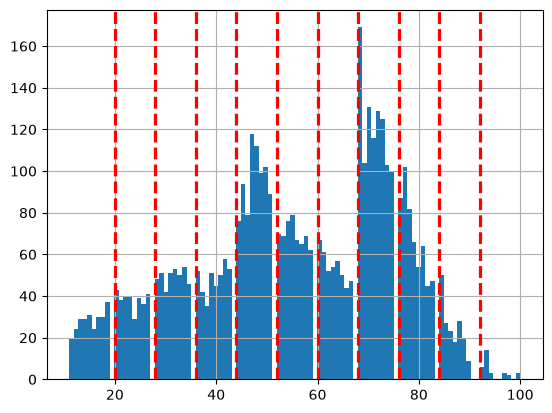

In [178]:
spotify_tracks['track_popularity'].hist(bins=100)
for idx in [20,28,36,44,52,60,68,76,84,92]:
    plt.axvline(x=idx, color='red', linestyle='--',lw=2.3)
plt.show()

In [179]:
i = 0
while i < 100:
    print(i)
    i += 43

0
43
86


So high is 0 <= x < 43, medium is 43 <= x < 86, high is above 86

In [186]:
def get_track_pop_class(x):
    if x < 43:
        return 'low'
    if x < 86:
        return 'medium'
    else:
        return 'high'

def amplify_high_pop(x):
    if x == 'high':
        return(10)
    else:
        return(3)


    
spotify_tracks['track_pop_class'] = spotify_tracks['track_popularity'].apply(get_track_pop_class)
spotify_tracks['track_pop_class_ptsz'] = spotify_tracks['track_pop_class'].apply(amplify_high_pop)
spotify_tracks['track_pop_class']

0       high
1       high
2       high
3       high
4       high
        ... 
4824     low
4825     low
4826     low
4827     low
4828     low
Name: track_pop_class, Length: 4829, dtype: str

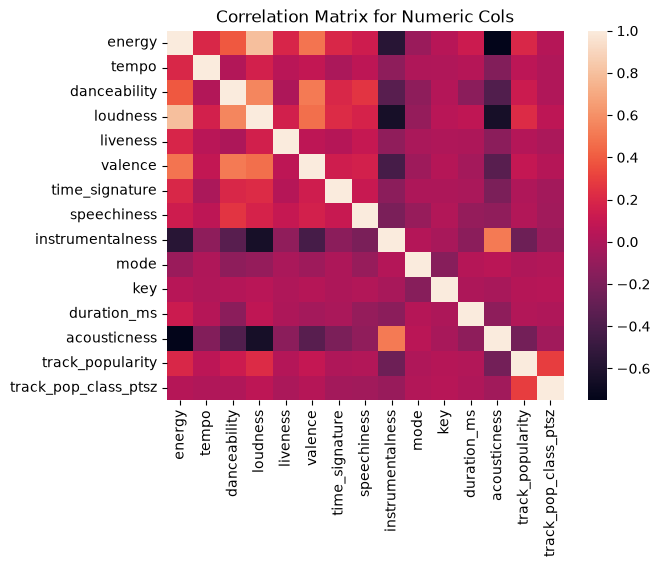

In [187]:
corr_df = spotify_tracks.corr(method='pearson',numeric_only=True)

sns.heatmap(data=corr_df)
plt.title("Correlation Matrix for Numeric Cols")
plt.show()



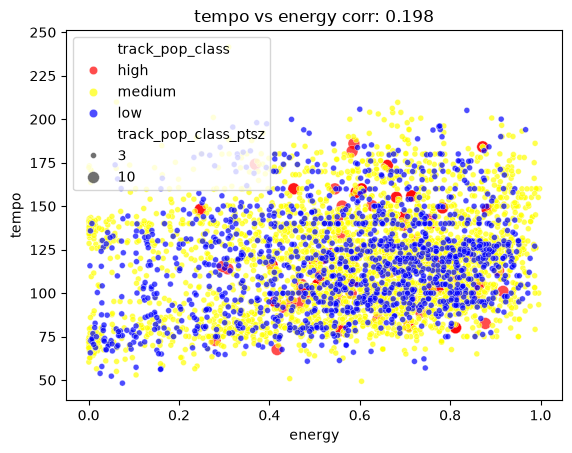

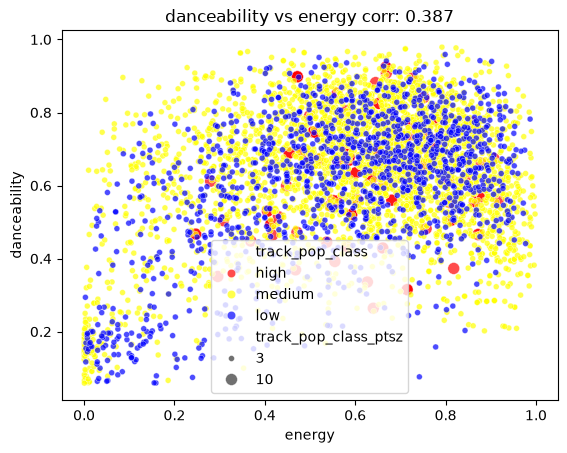

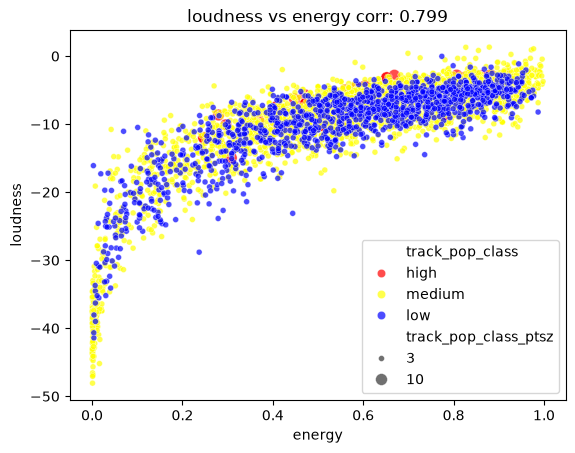

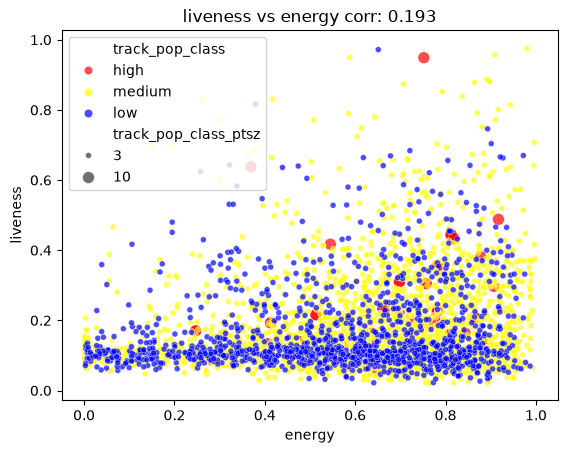

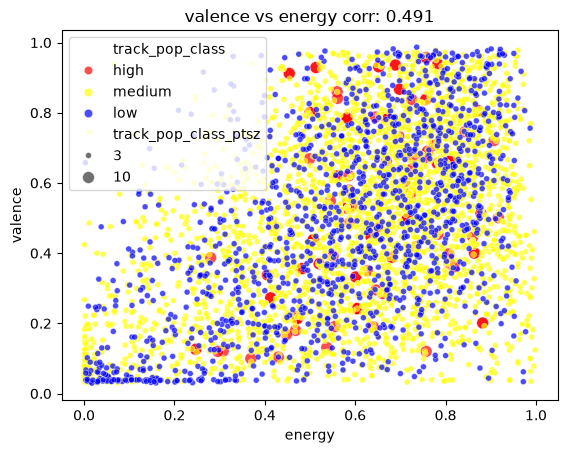

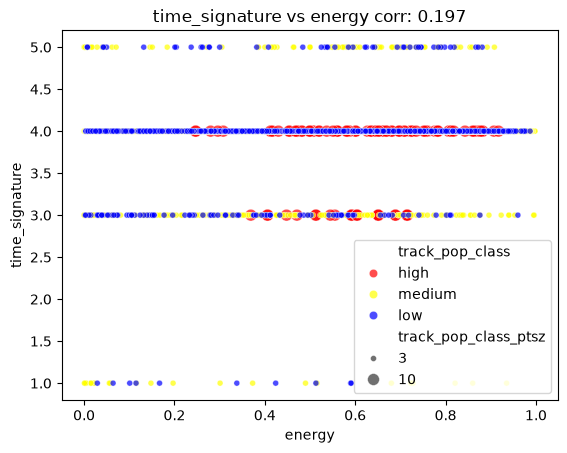

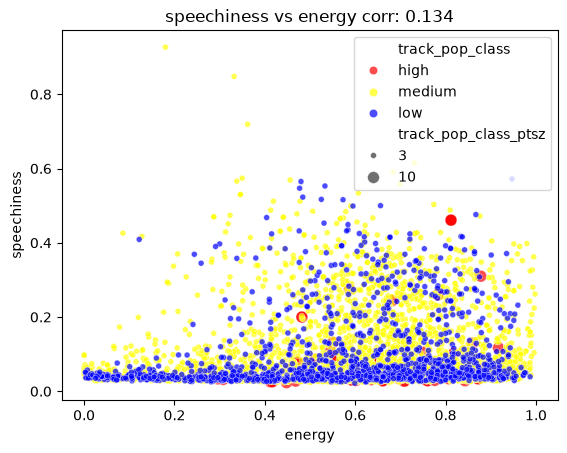

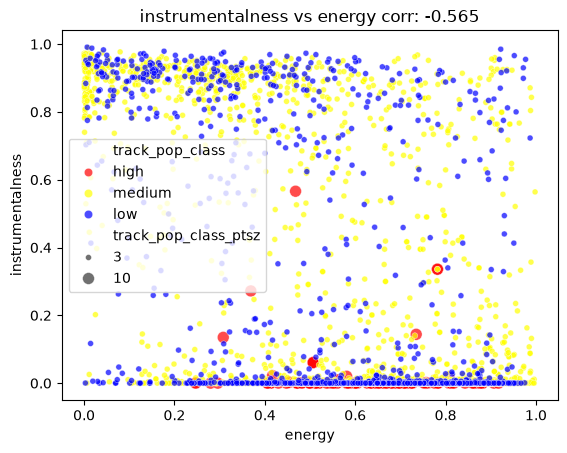

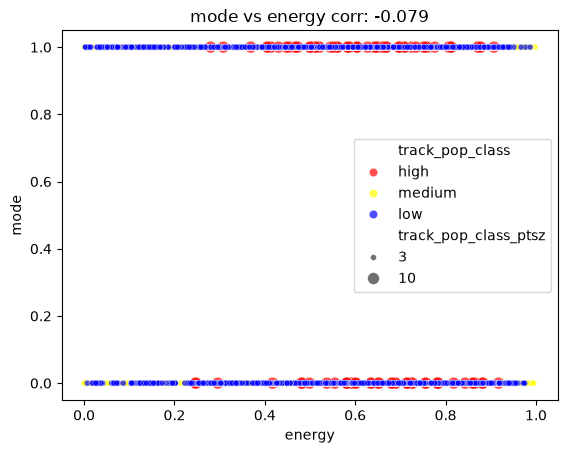

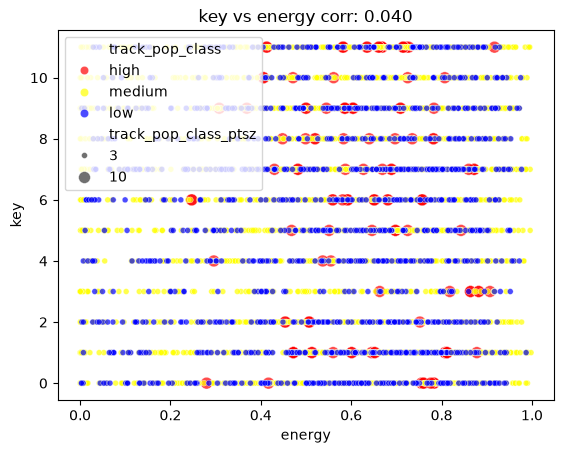

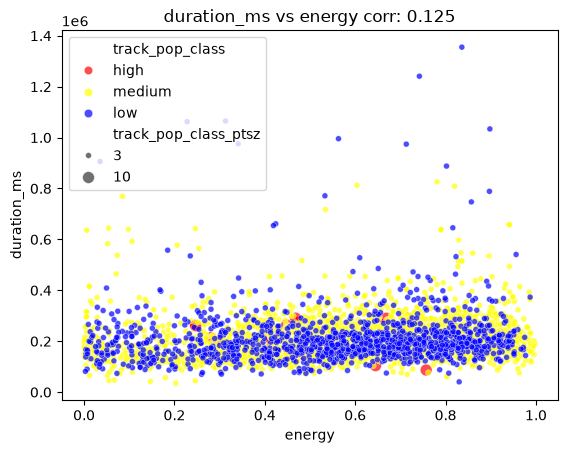

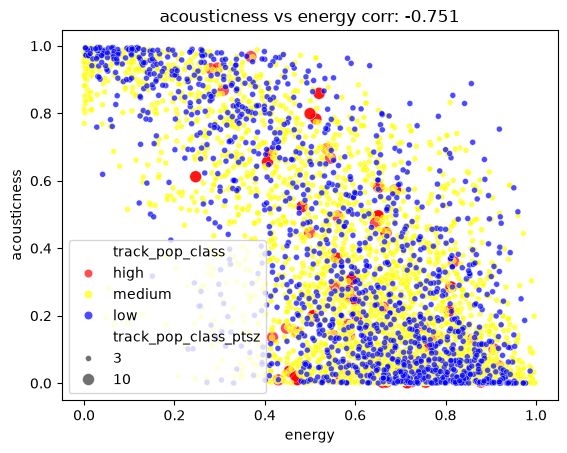

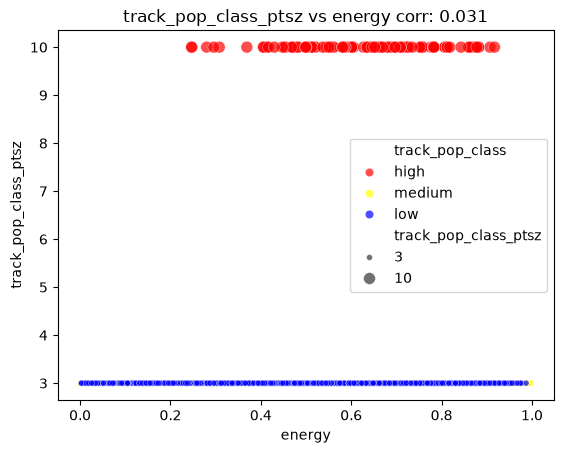

In [189]:
for col in corr_df.columns:
    if col != 'energy' and col != 'track_popularity':
        sns.scatterplot(data=spotify_tracks,x='energy',hue='track_pop_class',y=col,alpha=0.7,palette={"low": "blue","medium":"yellow","high":"red"},size='track_pop_class_ptsz')
        plt.title(f"{col} vs energy corr: {corr_df.loc['energy',col]:.3f}")
        plt.show()